# Segmentación de imágenes: binarización y K-means

Segmentación de una imagen de flores (flores / hojas / fondo) con Python, OpenCV y scikit-learn.

- **Parte 1:** binarización con umbral manual (elegido con el histograma) y con el método de Otsu.
- **Parte 2:** clustering K-means sobre los píxeles, con las 3 bandas RGB y con la banda verde + diferencia verde-rojo.

Requiere el archivo `flores.png` en la misma carpeta.

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

## Parte 1: Binarización

**Objetivo:** separar las flores del fondo usando un umbral sobre la imagen en escala de grises.

144000 cantidad de datos
(240, 200, 3)  dimensión de la imagen
Tipo de dato: uint8


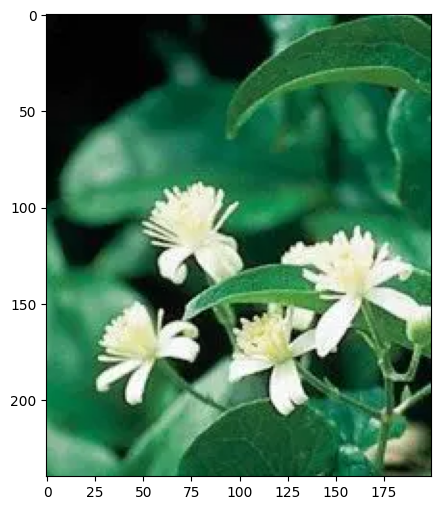

In [2]:
#Leo la imagen
img = cv2.imread('flores.png') #Open cv invierte los canales en BGR
### cracteristicas de la iamgen
print(img.size, 'cantidad de datos') #cantidad de pixeles: suma de pixeles de cada matriz RGB
print(img.shape,' dimensión de la imagen') #(filas, col, cantidad de bandas)
print('Tipo de dato:',img[0,0,0].dtype) #uint8 va de 0 a 255
#Pasamos a RGB la imagen
img_RGB=img.copy()
img_RGB=img[:,:,[2,1,0]] #pasamos a RGB
#Graficamos la imagen RGB
plt.figure(figsize=(6,6))
plt.imshow(img_RGB)
plt.show()

/tmp/ipykernel_525/914788413.py:13: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  axs[1].hist(img_mono.ravel(), 256,[0,256] ) #


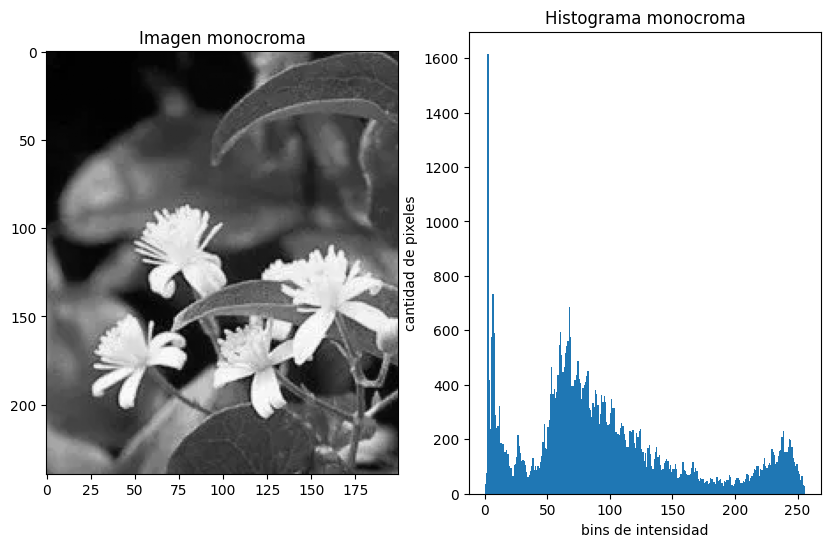

In [4]:
#PASAMOS LA IMAGEN A MONOCROMA
img_mono = cv2.imread('flores.png',0) #monocroma

#GRAFICAMOS EL HISTOGRAMA

fig, axs = plt.subplots(nrows=1, ncols=2, sharex=False)
axs=axs.ravel()
fig.set_figheight(6)
fig.set_figwidth(10)
axs[0].imshow(img_mono, cmap='gray',vmin=0 ,vmax=255)
axs[0].set_title('Imagen monocroma')

axs[1].hist(img_mono.ravel(), 256,[0,256] ) #
axs[1].set_xlabel('bins de intensidad')
axs[1].set_ylabel('cantidad de pixeles')
axs[1].set_title('Histograma monocroma')
plt.show()

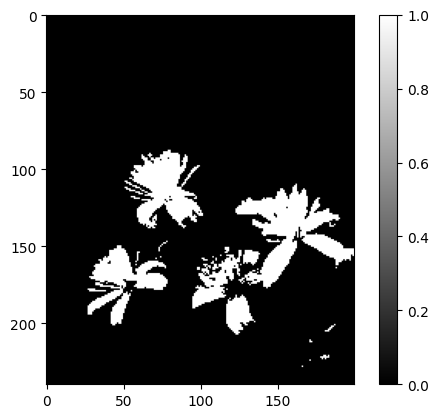

dtype('bool')

In [5]:
#QUEREMOS BINARIZAR LA IMAGEN SEPARANDO LAS FLORES DEL FONDO
#METODO MANUAL
#Elijo el umbral de intensidad a partir del cual voy a dividir la imagen en 2 grupos dándole el valor de 255 (blanco) a los pixeles con intensidad mayor
#al umbral y un valor 0 (negro)a los pixeles con intensidad menor al umbral propuesto.
#El umbral lo elijo observando el histograma ("a ojo"). Identifico como pixeles de las flores como el cluster entre aprox 200 y 255.
#Luego voy modificando el umbral para mejorar la binarización.

umbral=210
binaria_a_mano= img_mono>= umbral
plt.imshow(binaria_a_mano, cmap='gray')
plt.colorbar()
plt.show()
binaria_a_mano.dtype

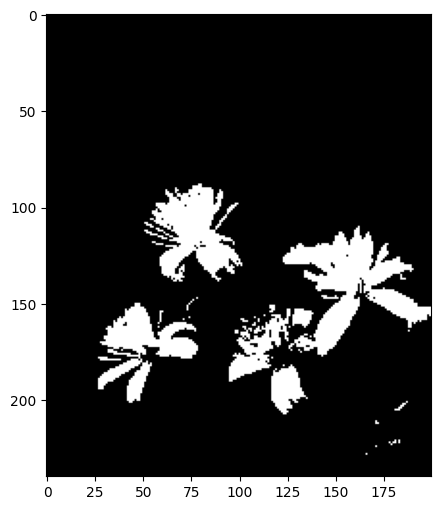

In [6]:
# la funcion threshold de OpenCV se utiliza para la binarización de imágenes.
#manual
ret,binaria = cv2.threshold(img_mono,umbral,255,cv2.THRESH_BINARY) #THRESH_BINARY, significa que si el valor del píxel es mayor que el umbral, se establecerá en el valor máximo (255 en este caso), de lo contrario, se establecerá en cero (0).
#GRAFICAMOS LA IMAGEN
plt.figure(figsize=(6,6))
plt.imshow(binaria, cmap='gray',vmin=0 ,vmax=255)
plt.show()


In [7]:
#Automatizado
#Metodo Otsu para elección del umbral
#Elige un umbral para separar los pixeles en 2 clases, intentando que la varianza en cada clase sea mínima y la varianza entre las 2 clases sea máxima.
ret0,binaria0 = cv2.threshold(img_mono,0,255,cv2.THRESH_OTSU) #thresh_otsu calcula el umbral con la varianza
print(img.dtype,binaria0.dtype,'umbral:', ret0)

uint8 uint8 umbral: 129.0


umbral calculado por Otsu: 129.0


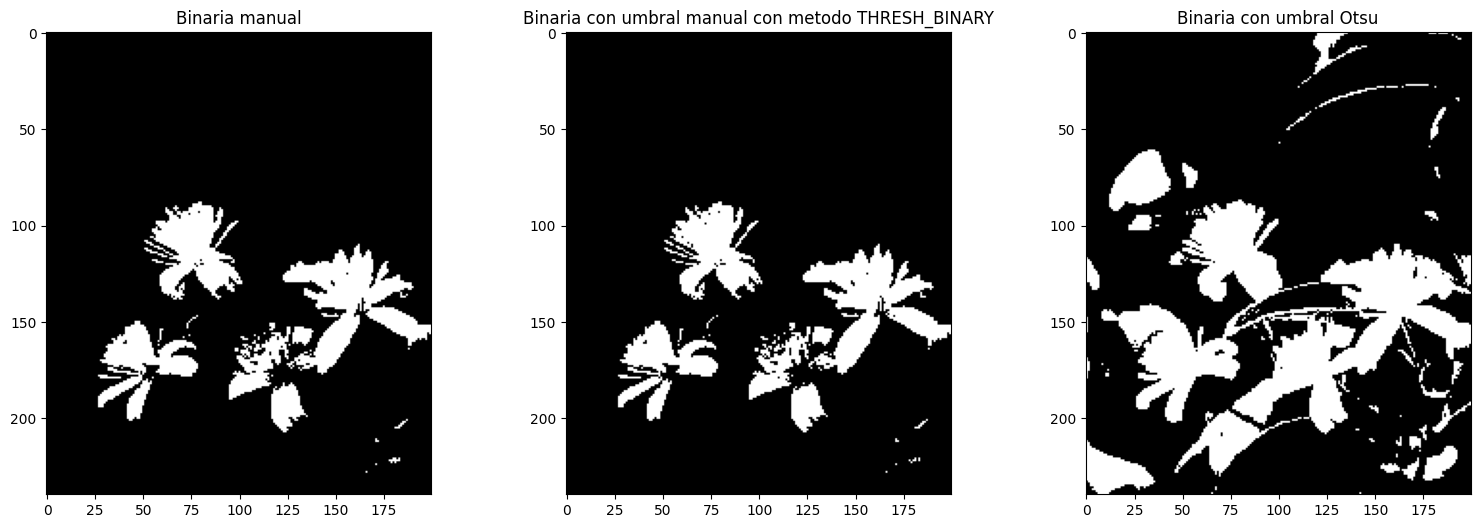

In [8]:
#Comparo las imagenes obtenidas

fig, axs = plt.subplots(nrows=1, ncols=3)
fig.set_figheight(6)
fig.set_figwidth(19)
axs[0].imshow(binaria_a_mano, cmap='gray')
axs[0].set_title('Binaria manual')

axs[2].imshow(binaria0, cmap='gray',vmin=0 ,vmax=255)
axs[2].set_title('Binaria con umbral Otsu')


axs[1].imshow(binaria, cmap='gray',vmin=0 ,vmax=255)
axs[1].set_title('Binaria con umbral manual con metodo THRESH_BINARY')

print('umbral calculado por Otsu:', ret0)

Obtuvimos un mejor resultado de binarización con el método manual ya que Otsu no siempre funciona bien al elegir el umbral. Otsu asume que la imagen tiene una distribución bimodal de niveles de gris (dos picos en el histograma), uno para el fondo y otro para el objeto. Si hay múltiples objetos con diferentes niveles de gris el histograma puede no ser claramente bimodal, lo que dificulta la elección de un umbral adecuado.

Para mejorar los resultados de la umbralización en estos casos, se podría considerar:

-Aplicar técnicas de filtrado para reducir el ruido, como el filtro gaussiano, puede mejorar los resultados.
-Usar técnicas de corrección de iluminación
-En lugar de usar un único umbral para toda la imagen, se puede usar umbralización adaptativa (cv2.adaptiveThreshold), que calcula diferentes umbrales para diferentes regiones de la imagen, teniendo en cuenta la variación de iluminación.

## Parte 2: Clustering (K-means)

## Parte 2: Clustering (K-means)

**Objetivo:** segmentar la imagen en tres regiones (flores, hojas y fondo) con K-means, sin etiquetas previas.

1. Convertir la imagen en un DataFrame con un píxel por fila.
2. Entrenar K-means con 3 clusters, primero usando las bandas RGB. Graficar los clusters en el espacio RGB y sobre la imagen, y evaluar si el resultado fue el esperado.
3. Mostrar lado a lado la imagen original, la imagen segmentada en 3 niveles de gris y la imagen binarizada de la parte 1, y comparar semejanzas y diferencias.

In [9]:
import pandas as pd
# Librerías para Clustering
from sklearn.cluster import KMeans, DBSCAN
from sklearn import preprocessing
from sklearn.metrics import silhouette_score
from collections import Counter

In [10]:

#Pasamos RGB a dataframe
dims=img_RGB.shape
cant_filas=dims[0]
cant_columnas=dims[1]
ind=np.indices((cant_filas,cant_columnas)) # arreglo con matriz de filas y  matriz de columnas

cant_pixeles=cant_filas*cant_columnas
columnas=np.zeros([cant_pixeles,5],dtype='int')

data0=np.zeros([cant_pixeles,5],dtype='int')
data0[:,0]=ind[0].flatten() #filas
data0[:,1]=ind[1].flatten() #columnas
data0[:,2]=img_RGB[:,:,0].flatten() #rojo
data0[:,3]=img_RGB[:,:,1].flatten() # verde
data0[:,4]=img_RGB[:,:,2].flatten() # azul

df = pd.DataFrame(data0, columns=["fila", "columna","rojo","verde","azul"])

print(df.shape)
print('Base de pixeles:')
df.head() # 48000 pixeles y por cada pixel 5 columnas con sus datos

(48000, 5)
Base de pixeles:


,fila,columna,rojo,verde,azul
0,0,0,7,7,7
1,0,1,7,7,7
2,0,2,7,7,7
3,0,3,7,7,7
4,0,4,8,8,8


In [11]:
X=data0[:,2:5] #no estandarizo los datos porque las bandas de RGB van todas de 0 a 255
print(X)
# Se agrupan los datos usando Kmedias en 3 clusters (cantidad elegida de forma arbitraria) para ver que da con las 3 bandas
kmeans = KMeans(n_clusters=3)
kmeans.fit(X)

[[  7   7   7]
 [  7   7   7]
 [  7   7   7]
 ...
 [ 77 110  76]
 [ 83 116  82]
 [ 97 131  94]]


KMeans(n_clusters=3)

In [12]:
# resultados
print(kmeans.labels_)
print(kmeans.labels_.shape)

[2 2 2 ... 1 1 1]
(48000,)


In [13]:
df_clusters=df.copy() #nuevo Data Frame
df_clusters['kmedias_3']=kmeans.labels_#la agrego a mi nueva base de ddatos
df_clusters.head()

,fila,columna,rojo,verde,azul,kmedias_3
0,0,0,7,7,7,2
1,0,1,7,7,7,2
2,0,2,7,7,7,2
3,0,3,7,7,7,2
4,0,4,8,8,8,2


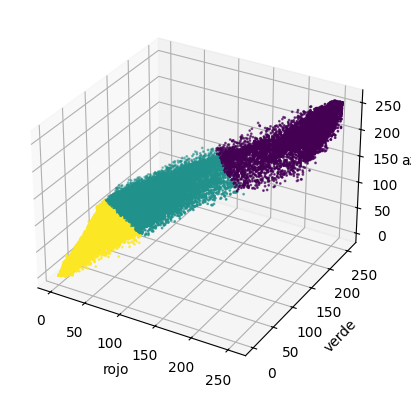

In [14]:
from mpl_toolkits.mplot3d import Axes3D
variables=["rojo","verde","azul"]
fig = plt.figure()

# Crear un objeto Axes3D
ax = fig.add_subplot(111, projection='3d')
ax.scatter(df[variables[0]].values, df[variables[1]].values, df[variables[2]].values,c=kmeans.labels_, s=1)
# Etiquetas de los ejes
ax.set_xlabel(variables[0])
ax.set_ylabel(variables[1])
ax.set_zlabel(variables[2])
plt.show()
#encuentra 3 grupos dividido en intensidades

In [15]:
#voy a hacer otra relacion de variables tengio que hacer mi matriz de al mneos 2columnas para usar de nuevo el Kmeans
X_nuevo=np.zeros([cant_pixeles,2],dtype='int')# quiero dos columnas piorque voy a usar la banda verde y la dif v-r
#de forma matricial
X_nuevo[:,0]=data0[:,3] #g
X_nuevo[:,1]=data0[:,3]-data0[:,2]# v-r
#Vamos a estandarizar los datos a usar antes de aplicar el Kmeans asi convertimos las características a una escala común, con una media de 0 y
#una desviación estándar de 1. Esto evita que las características con mayores valores numéricos dominen la formación de los clusters.
# Estandarizamos los datos
std_scale=preprocessing.StandardScaler().fit(X_nuevo) #resta la media  de cada columna y luego divide por el desvío
df_estandarizadas=std_scale.transform(X_nuevo) # media 0 y desvío 1 por columnas

In [16]:
print(df_estandarizadas)
print(np.shape(df_estandarizadas[:,1]))
np.shape(df['verde'].values)

[[-1.61649241 -1.51664965]
 [-1.61649241 -1.51664965]
 [-1.61649241 -1.51664965]
 ...
 [-0.07398185 -0.56148377]
 [ 0.01587313 -0.56148377]
 [ 0.24051059 -0.53253935]]
(48000,)


(48000,)

In [17]:
#aplicar K-means
num_clusters = 3  # número deseado de clusters
kmeans_1 = KMeans(n_clusters=num_clusters, random_state=42)
kmeans_1.fit(df_estandarizadas)  #ejecuto el algoritmo usando la base estandarizada o normalizada por columna

# Agregar las etiquetas de los clusters al DataFrame original
df_clusters['kmeans_1'] = kmeans_1.labels_
# Mostrar los resultados
print(df_clusters.head())


   fila  columna  rojo  verde  azul  kmedias_3  kmeans_1
0     0        0     7      7     7          2         2
1     0        1     7      7     7          2         2
2     0        2     7      7     7          2         2
3     0        3     7      7     7          2         2
4     0        4     8      8     8          2         2


In [18]:
df['dif_g-r']=df["verde"]-df["rojo"] #genramos un nuevo indice con la dif de bandas
df.head()

,fila,columna,rojo,verde,azul,dif_g-r
0,0,0,7,7,7,0
1,0,1,7,7,7,0
2,0,2,7,7,7,0
3,0,3,7,7,7,0
4,0,4,8,8,8,0


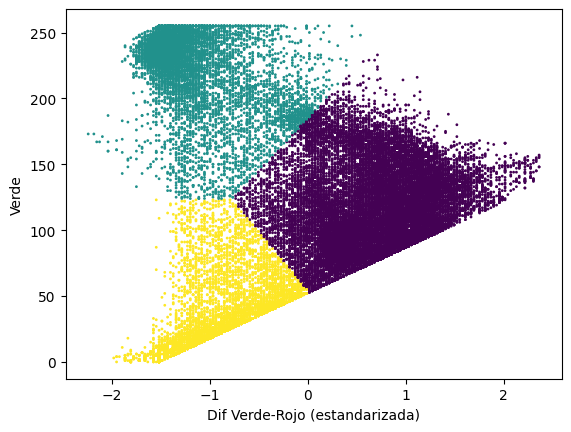

In [19]:
f1 = df_estandarizadas[:,1]
f2 = df['verde'].values
f3= kmeans_1.labels_

plt.scatter(f1, f2,c=f3, s=1)
plt.xlabel('Dif Verde-Rojo (estandarizada)')
plt.ylabel('Verde')
plt.show() #encuentro 3 grupos marcados

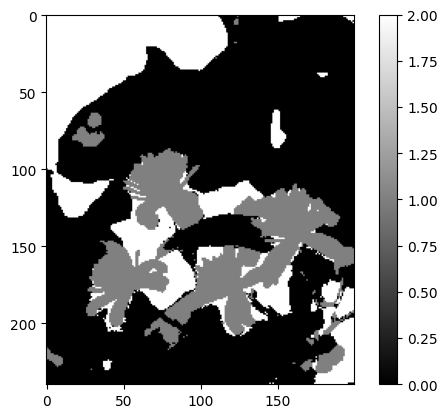

In [20]:
imagen_kmedias_dif=np.reshape(kmeans_1.labels_, (cant_filas,cant_columnas)) #creo mi matriz de etiquetas
plt.imshow(imagen_kmedias_dif, cmap='gray')
#plt.imshow(imagen_kmedias, cmap='gray')
#plt.title('imagen TRInaria')
plt.colorbar()
plt.show()

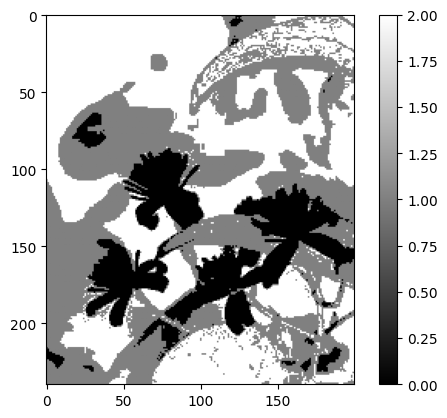

In [21]:
imagen_kmedias=np.reshape(kmeans.labels_, (cant_filas,cant_columnas)) #hago mi matriz de etiquetas
plt.imshow(imagen_kmedias, cmap='gray')
#plt.imshow(imagen_kmedias, cmap='gray')
#plt.title('imagen TRInaria')
plt.colorbar()
plt.show()

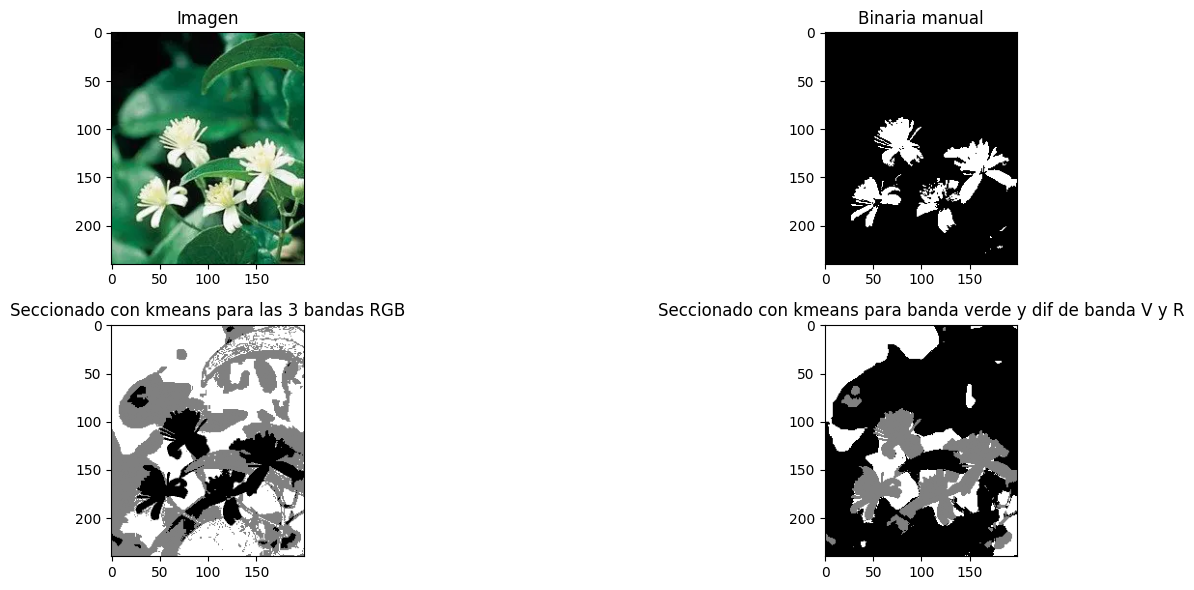

In [22]:
#Comparo las imagenes obtenidas

fig, axs = plt.subplots(nrows=2, ncols=2)
fig.set_figheight(6)
fig.set_figwidth(19)
axs[0,0].imshow(img_RGB) #,cmap='gray',vmin=0 ,vmax=255)
axs[0,0].set_title('Imagen')
axs[0,1].imshow(binaria_a_mano, cmap='gray')
axs[0,1].set_title('Binaria manual')
axs[1,0].imshow(imagen_kmedias, cmap='gray')
axs[1,0].set_title('Seccionado con kmeans para las 3 bandas RGB')
axs[1,1].imshow(imagen_kmedias_dif, cmap='gray')
axs[1,1].set_title('Seccionado con kmeans para banda verde y dif de banda V y R')
# Ajusta los espacios entre subtramas para evitar solapamientos
plt.tight_layout()





La imagen binarizada manualmente dio un resultado bastante bueno, incluso mejor que el obtenido mediante el método de Otsu.

En cuanto a la segmentación mediante K-means, probé dos alternativas y obtuve resultados diferentes en cuanto a la calidad de la separación.

En primer lugar, apliqué K-means utilizando las tres bandas RGB. La idea era explorar cómo se comportaba el algoritmo al trabajar directamente con la información de color de la imagen. Como se trata de una imagen con pocos detalles y variaciones de color, el algoritmo logró identificar los tres grupos que buscaba. En este resultado, la región negra corresponde principalmente a las flores y algunos otros detalles de mayor intensidad, la región blanca representa las hojas y la gris corresponde al fondo.

Luego probé una segunda alternativa, utilizando como variables la banda verde y la diferencia entre las bandas verde y roja. La elección de estas dos variables se basó en el comportamiento de las intensidades de cada banda. Por un lado, la banda verde por sí sola permite distinguir tres niveles: intensidades altas en las flores, intermedias en las hojas y muy bajas o prácticamente nulas en el fondo. Si bien las tres bandas presentan un comportamiento similar, la predominancia del color verde en la imagen hace que esta banda resulte particularmente útil para la separación.

Por otro lado, elegí la diferencia entre las bandas verde y roja porque, aunque sus valores máximos y mínimos de intensidad son similares, esperaba encontrar diferencias más marcadas entre ambas en los valores intermedios.

Entrené K-means utilizando estas dos variables y obtuve una segmentación de los tres grupos más definida que la conseguida con las tres bandas RGB. En este caso, la región gris corresponde a las flores, la negra a las hojas y la blanca al fondo.

In [23]:
print(img_RGB[230,100,:]) #hojas tiene mayoritaria verde, pero tambien azul
print(img_RGB[100,65,:]) #flor  mucha intensidad de los 3, mas rojo y verde
print(img_RGB[0,10,:]) #poca intensidad todos

[17 82 46]
[245 244 224]
[2 2 2]
